In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression


In [2]:
lin = LinearRegression
log = LogisticRegression

cancer = load_breast_cancer(as_frame=True)
type(cancer)

sklearn.utils._bunch.Bunch

In [3]:

# Load the dataset as a pandas DataFrame
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame

# Save the DataFrame as a CSV file on your machine
df.to_csv("breast_cancer.csv", index=False)

print("Dataset successfully saved as 'breast_cancer.csv' in your current working directory!")

Dataset successfully saved as 'breast_cancer.csv' in your current working directory!


In [4]:

# Load the data from your CSV
df = pd.read_csv("breast_cancer.csv")

# Check shape (rows, columns)
print("Shape of dataset:", df.shape)

# View the first 5 rows
display(df.head())

Shape of dataset: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [6]:
# Check data types and non-null counts
df.info()

# Check for any missing values across the entire dataset
print("\nMissing values per column:\n", df.isnull().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [7]:
# Get statistical summary
summary = df.describe()
display(summary)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [8]:
# Check the count of each class in the target column
# (Usually, 0 = malignant, 1 = benign in sklearn's breast cancer dataset)
class_counts = df['target'].value_counts()
print(class_counts)

# Let's see the percentage breakdown
print("\nPercentage breakdown:")
print(df['target'].value_counts(normalize=True) * 100)

target
1    357
0    212
Name: count, dtype: int64

Percentage breakdown:
target
1    62.741652
0    37.258348
Name: proportion, dtype: float64


In [9]:
# Swap the values: 0 becomes 1, and 1 becomes 0
df['target'] = df['target'].map({0: 1, 1: 0})

# Verify the new counts (1 = malignant, 0 = benign)
print("Updated target class counts:")
print(df['target'].value_counts())



Updated target class counts:
target
0    357
1    212
Name: count, dtype: int64


c:\Users\HP\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\HP\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\HP\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\HP\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

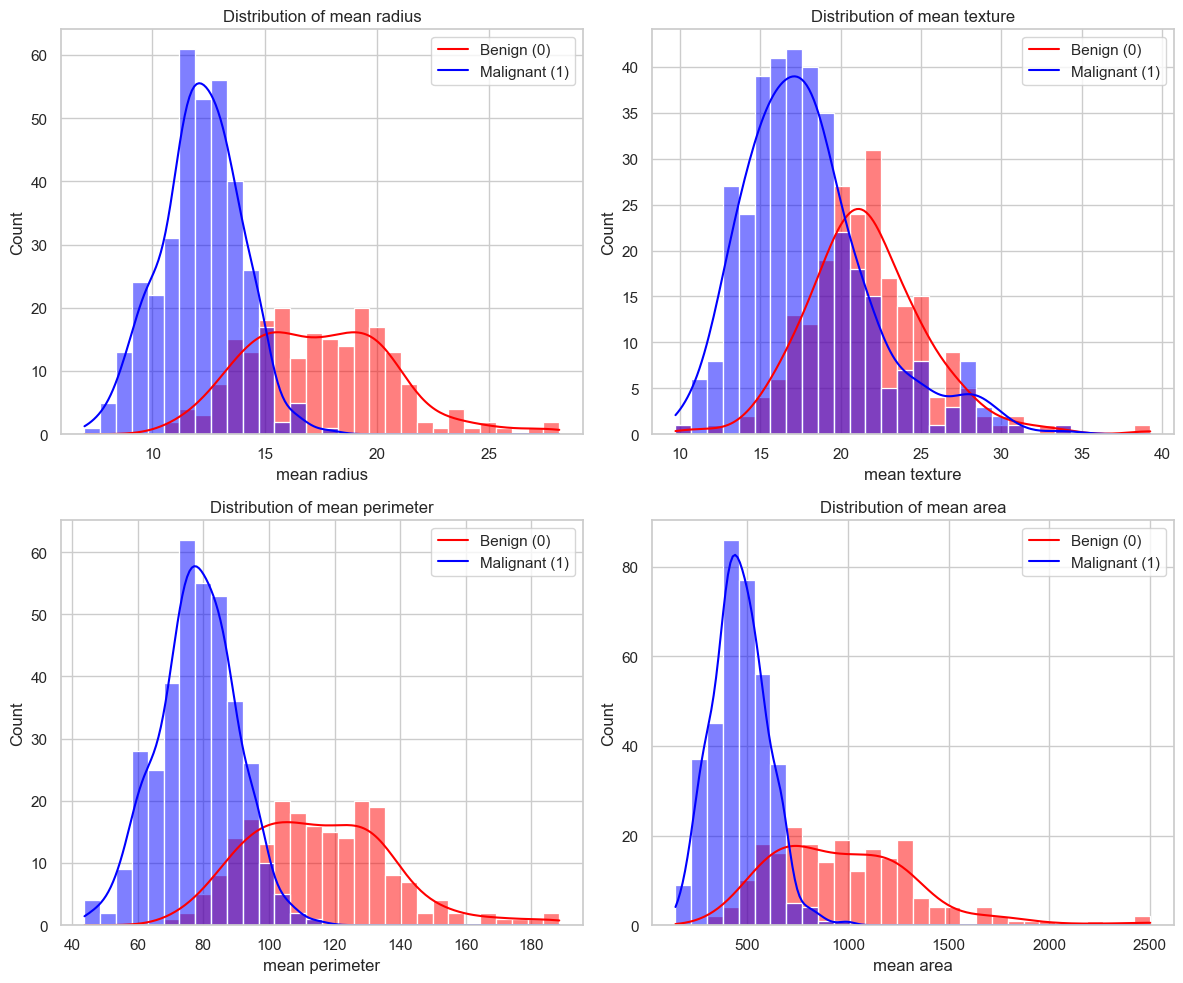

In [10]:

# Set the style
sns.set_theme(style="whitegrid")

# Let's pick a couple of features to visualize, e.g., 'mean radius' and 'mean texture'
features_to_plot = ['mean radius', 'mean texture', 'mean perimeter', 'mean area']

plt.figure(figsize=(12, 10))
for i, feature in enumerate(features_to_plot):
    plt.subplot(2, 2, i + 1)
    # Plot histogram separated by target class
    sns.histplot(data=df, x=feature, hue='target', kde=True, palette={0: 'blue', 1: 'red'}, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.legend(['Benign (0)', 'Malignant (1)'])

plt.tight_layout()
plt.show()

In [11]:


cancer = load_breast_cancer()
print(cancer.DESCR)  # This prints a detailed summary of all 30 features and their descriptions

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

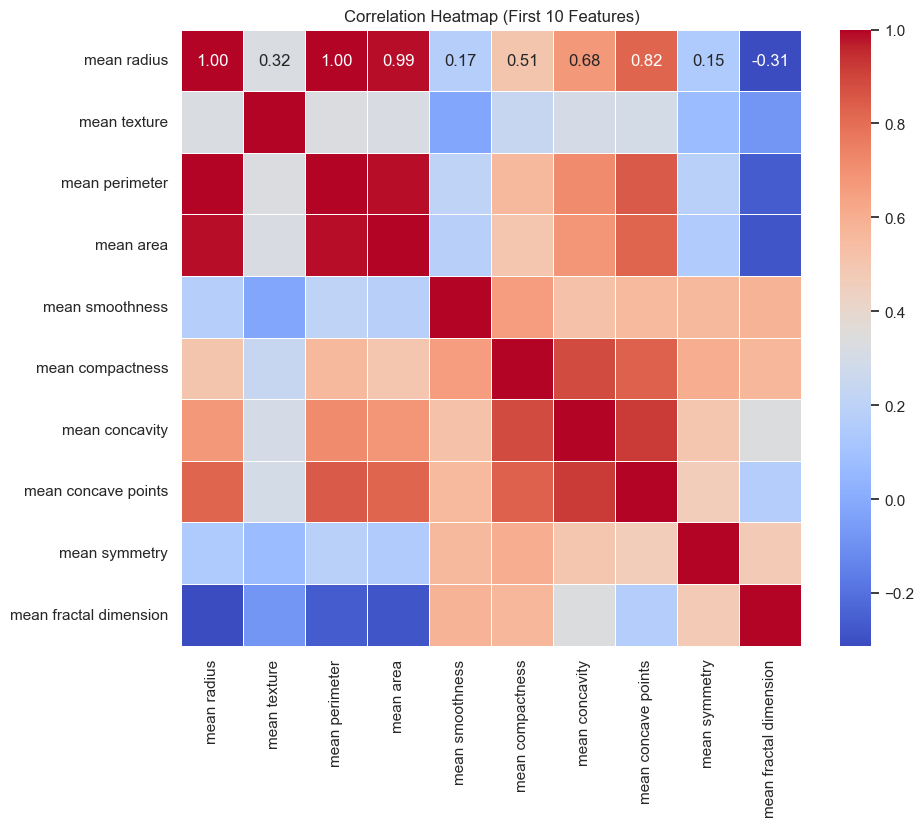

In [12]:
# Compute the correlation matrix for the first 10 features to keep the plot readable
corr_matrix = df.iloc[:, :10].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap (First 10 Features)")
plt.show()

In [13]:

from sklearn.preprocessing import StandardScaler

# 2. Separate features (X) and target (y)
X = df.drop(columns=['target'])
y = df['target']

# 3. Initialize the StandardScaler
scaler = StandardScaler()

# 4. Fit and transform the features
# This converts every feature to have a mean of 0 and a standard deviation of 1
X_scaled_array = scaler.fit_transform(X)

# 5. Convert the resulting NumPy array back into a pandas DataFrame with original column names
X_scaled_df = pd.DataFrame(X_scaled_array, columns=X.columns)

# 6. Re-attach the target column if you want a complete standardized dataframe
df_scaled = X_scaled_df.copy()
df_scaled['target'] = y.values

# Preview the standardized data (notice how means are ~0 and values are centered)
print(df_scaled.head())
print("\nNew Summary Statistics (Check means and stds):")
print(df_scaled.iloc[:, :5].describe().round(2)) # Looking at the first 5 features

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0     1.097064     -2.073335        1.269934   0.984375         1.568466   
1     1.829821     -0.353632        1.685955   1.908708        -0.826962   
2     1.579888      0.456187        1.566503   1.558884         0.942210   
3    -0.768909      0.253732       -0.592687  -0.764464         3.283553   
4     1.750297     -1.151816        1.776573   1.826229         0.280372   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0          3.283515        2.652874             2.532475       2.217515   
1         -0.487072       -0.023846             0.548144       0.001392   
2          1.052926        1.363478             2.037231       0.939685   
3          3.402909        1.915897             1.451707       2.867383   
4          0.539340        1.371011             1.428493      -0.009560   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score

# 1. Split our pure features (X_scaled_df) and target (df_scaled['target'])
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled_df, 
    df_scaled['target'], 
    test_size=0.2, 
    random_state=42, 
    stratify=df_scaled['target']
) #Use stratify to enable class balance and to avoid class inbalance

# 2. Train the Logistic Regression model
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train, y_train)

# 3. Make predictions on the test set
y_pred = model.predict(X_test)

# 4. Evaluate performance
print(f"Accuracy Score: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))

Accuracy Score: 96.49%

Classification Report:
               precision    recall  f1-score   support

   Benign (0)       0.96      0.99      0.97        72
Malignant (1)       0.97      0.93      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.96      0.96       114
 weighted avg       0.97      0.96      0.96       114



In [15]:

# Create a comparison DataFrame for the first 10 test samples
comparison_df = pd.DataFrame({
    'Actual (y_test)': y_test.values[:10],
    'Predicted (y_pred)': y_pred[:10]
})

# Display the table
print(comparison_df)

   Actual (y_test)  Predicted (y_pred)
0                0                   0
1                1                   1
2                0                   0
3                1                   1
4                0                   1
5                0                   0
6                1                   1
7                0                   0
8                0                   0
9                0                   0


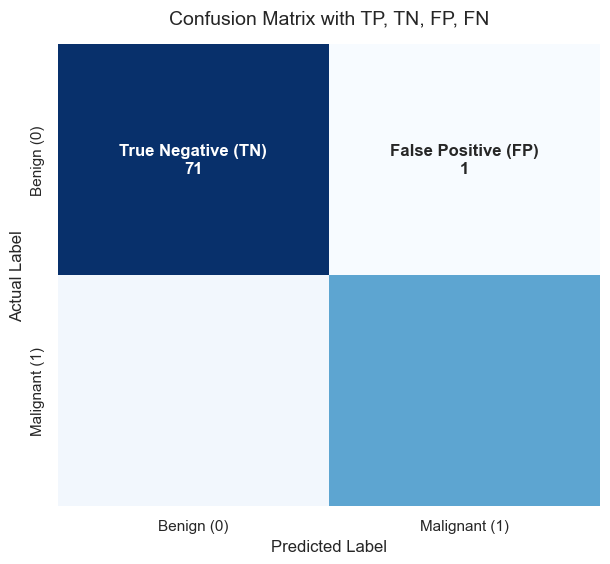

In [16]:

from sklearn.metrics import confusion_matrix


# 1. Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# 2. Create custom annotation labels combining the counts with their terms
# cm[0, 0] = TN, cm[0, 1] = FP, cm[1, 0] = FN, cm[1, 1] = TP
labels = np.array([
    [f"True Negative (TN)\n{cm[0, 0]}", f"False Positive (FP)\n{cm[0, 1]}"],
    [f"False Negative (FN)\n{cm[1, 0]}", f"True Positive (TP)\n{cm[1, 1]}"]
])

# 3. Plot the heatmap using the custom labels
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Benign (0)', 'Malignant (1)'],
            yticklabels=['Benign (0)', 'Malignant (1)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.title('Confusion Matrix with TP, TN, FP, FN', fontsize=14, pad=15)
plt.show()

In [17]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

acc = accuracy_score(y_test, y_pred)

print(acc)

0.9649122807017544


In [20]:
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred
                            )


print(f"This is calculated precision: {precision}")
print(f"This is calculated recall: {recall}")

This is calculated precision: 0.975
This is calculated recall: 0.9285714285714286


In [21]:
y.value_counts()

target
0    357
1    212
Name: count, dtype: int64

In [23]:
357/212

1.6839622641509433

In [ ]:
##Decision Tree

"""
When linear regression fails, the next step is to have to try decison tree.
This is after you have done some things like adding data, hyperparameter tuning but the 
model is not responding. 

The tree learns which question to ask. The decision tree does not necessary have a linear regression model. 
It learns the model depending on the parameters that you have.

Metrics remain more/less the same.
"""

In [18]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=254,min_samples_leaf=15, max_depth=50)

#fitting the model
tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",50
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",254
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [40]:
#prediction
y_pred_tree = tree.predict(X_test)

acc_tree = accuracy_score(y_test, y_pred_tree)
prec_tree = precision_score(y_test, y_pred_tree)
recall_tree = recall_score(y_test, y_pred_tree)

print(f"This is precision : {prec_tree} for decision tree")
print(f"This is recall : {recall_tree} for decision tree")
print(f"This is accuracy : {acc_tree} for decision tree")

This is precision : 0.925 for decision tree
This is recall : 0.8809523809523809 for decision tree
This is accuracy : 0.9298245614035088 for decision tree


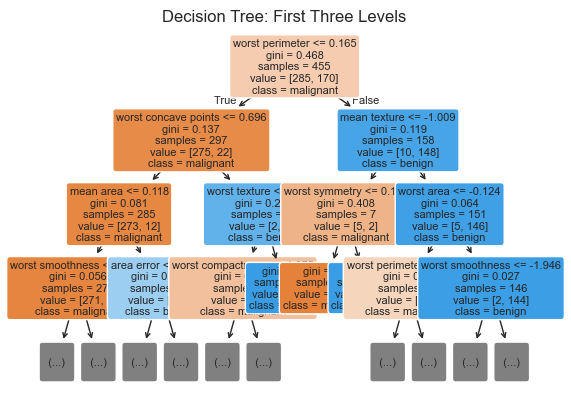

In [41]:
from sklearn.tree import plot_tree
plot_tree(
    tree,
    feature_names=cancer.feature_names,
    class_names=cancer.target_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree: First Three Levels")
plt.show()

In [ ]:
""".
Cross validation- You randomly split your data as training and testing set 5 diffrent times


"""

In [43]:
X_train.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
10,0.537556,0.919273,0.442011,0.406453,-1.017686,-0.713542,-0.700684,-0.404686,-1.035476,-0.826124,...,0.604849,1.335771,0.492622,0.473611,-0.625477,-0.630828,-0.605872,-0.226210,0.076431,0.031819
170,-0.513297,-1.605595,-0.540376,-0.542624,0.458285,-0.654413,-0.614306,-0.307442,0.538081,-0.460382,...,-0.573451,-1.634499,-0.604391,-0.582718,0.268776,-0.812128,-0.709978,-0.315133,-0.119321,-0.899721
407,-0.362769,0.484112,-0.384677,-0.399281,-1.483819,-0.401411,-0.345755,-0.780246,-0.845627,-0.234983,...,-0.387077,0.217034,-0.465589,-0.412728,-1.681045,-0.385914,-0.424046,-0.892221,-0.667748,-0.134983
430,0.219460,0.754052,0.417297,0.085638,0.221305,2.239288,2.316401,1.243034,0.837458,0.876418,...,0.016734,0.308227,0.540279,-0.084174,0.417818,2.892750,3.021056,2.023520,-0.056227,1.748601
27,1.273153,0.223480,1.241101,1.248876,-0.139504,0.042812,0.755818,0.732313,-0.418466,-0.823289,...,1.043864,0.257745,0.972174,0.918363,0.062747,-0.270773,0.347396,0.523700,-0.905562,-0.539518


In [ ]:
#F1 score
"""The F1 score is a metric used in machine learning and statistics to measure a model's accuracy. 
It is especially useful when dealing with classification problems where the classes are
imbalanced (e.g., when you have many more negative examples than positive ones).

The F1 score ranges from 0 to 1 (or 0% to 100%).

A score of 1 represents perfect precision and recall.

A score of 0 means the model's predictions are completely uninformative or incorrect.


- F_1 Score (beta = 1): Equal balance between precision and recall.

- F_{0.5} Score (beta = 0.5): Gives higher weight to precision (useful when false positives are costly, e.g., spam detection).

- F_2 Score (beta = 2): Gives higher weight to recall (useful when false negatives are critical, e.g., medical diagnostics or screening tests).
"""



In [ ]:
""" 
##Gini Impurity, Entropy and Log Loss

Gini Impurity- Measures the likelihood that a random chosen element from a 
dataset would be incorrectly labeled if were randomly labeled according to 
the distribution of labels in the subset

Purpose- Used as the default splitting cretireon in algorithms like classificaton &
regression trees to choose the best feature and split point at each node

Goal- Minimizee Gini impurity(a value of 0 means complete purity/homogeneity


- Entropy(and Information Gain)
Entropy comes from Information Theory(Claude Shannon) and measures the level of disorder,
randomness, or uncertainity in a dataset.

Purpose - Is used in decision tree algorithms like C4.5 and ID3 to calculate 
Information Gain (the reduction in entropy achieved by splitting on a feature)

Goal is to minimize entropy where a value of 0 means that we are completely certain

- Log Loss (Binary / Multi-Class Cross-Entropy)
Is an evaluation and optimization Loss Function used across probabilistic classifiers
such as Gradienet Boosted Trees like XGBoost and Logistic Regression

Purpose- Penalizes false classifications based on the predicted probabilities rather than
just the descrete class prediction

Features- Heavily penalizes predictions that are confident and wrong e,g
peredicting a 99% probabilities for Class A when the true label is Class B


"""

In [ ]:
##Ensemmbled Learning
"""Picks the best perfoming tree from 
Is the combination of mutliple models to pick the best ones

Techniques
1. Bagging- Kutengeneza a bunch of models then unavote, maybe 3 zimesema
benine 1 imesema malignant so you pick the benine one

"""

In [ ]:
##Random Forest
""".
It adds the idea of random feature selection
"""

In [44]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=254)
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",254
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootst

In [ ]:
#Boosting

""".
Developing model sequencially,
Model B is boosted from errors that were gotten from model A
Model C learns from the shortcomings from the previous model 
and imporoves the model"""

In [ ]:
#Stacking
